# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: Dataset Title: Wine Quality Dataset (Red and White Vinho Verde Wines)

Publisher/Creator: UCI Machine Learning Repository; created by Paulo Cortez, A. Cerdeira, F. Almeida, T. Matos, and J. Reis.

Direct Source URL:
 https://archive.ics.uci.edu/dataset/186/wine+quality

Data Dictionary / Feature Documentation:
 The variable descriptions are provided on the UCI dataset page under "Variables" and "Additional Variable Information," which documents all physicochemical measurements and the quality score.

Access Date: November 8, 2026.

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: Each row represents a single wine sample from the Portuguese Vinho Verde wine region. The dataset contains separate collections of red and white wines and includes measurements from physicochemical laboratory tests along with a quality rating assigned by wine experts. The dataset covers wine samples collected for a study of Portuguese Vinho Verde wines. The UCI documentation states that the records contain physicochemical measurements and sensory quality evaluations but does not specify an exact collection period. Observations were collected through laboratory testing of wine characteristics such as fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, and alcohol content. Wine quality was evaluated by wine experts and recorded on a scale from 0 to 10. A useful categorical feature for comparison is wine type (red versus white wine). The dataset also contains numerous quantitative measurements including alcohol content, pH, density, residual sugar, sulphates, chlorides, and acidity measures, satisfying the requirement for multiple quantitative variables. This dataset is especially good for the lab because you can compare distributions between red and white wines using histograms, box plots, and violin plots, just like the assignment asks


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I confirmed that this dataset has not been used in class or any of my previous lab submissions by reviewing the datasets listed in the course materials and comparing them to my prior assignments. The examples specifically mentioned as previously used datasets include Billboard number-one songs, Titanic passengers, Pokémon, and penguins.


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [3]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [129]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
telco_customer_df = pd.read_csv("data/telco_customer_churn.csv")

In [130]:
# Display the first five rows.
telco_customer_df.head()


,customer_id,contract,internet_service,tech_support,payment_method,paperless_billing,churn
0,7590-VHVEG,Month-to-month,DSL,No,Electronic check,Yes,No
1,5575-GNVDE,One year,DSL,No,Mailed check,No,No
2,3668-QPYBK,Month-to-month,DSL,No,Mailed check,Yes,Yes
3,7795-CFOCW,One year,DSL,Yes,Bank transfer (automatic),No,No
4,9237-HQITU,Month-to-month,Fiber optic,No,Electronic check,Yes,Yes


In [131]:
# Display the last five rows.
telco_customer_df.tail()

,customer_id,contract,internet_service,tech_support,payment_method,paperless_billing,churn
7038,6840-RESVB,One year,DSL,Yes,Mailed check,Yes,No
7039,2234-XADUH,One year,Fiber optic,No,Credit card (automatic),Yes,No
7040,4801-JZAZL,Month-to-month,DSL,No,Electronic check,Yes,No
7041,8361-LTMKD,Month-to-month,Fiber optic,No,Mailed check,Yes,Yes
7042,3186-AJIEK,Two year,Fiber optic,Yes,Bank transfer (automatic),Yes,No


In [132]:
# Display the DataFrame shape.
telco_customer_df.shape


(7043, 7)

In [133]:
# Display .info().
telco_customer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        7043 non-null   object
 1   contract           7043 non-null   object
 2   internet_service   7043 non-null   object
 3   tech_support       7043 non-null   object
 4   payment_method     7043 non-null   object
 5   paperless_billing  7043 non-null   object
 6   churn              7043 non-null   object
dtypes: object(7)
memory usage: 385.3+ KB


In [134]:
# Display missing-value counts for every feature.
telco_customer_df.isnull().sum()

customer_id          0
contract             0
internet_service     0
tech_support         0
payment_method       0
paperless_billing    0
churn                0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| customer_id | Unique customer identifier | Identifier | object | 0 |
| contract | Categorical | Categorical | object | 0 |
| internet_service | Internet service type (DSL, Fiber optic, etc.) | Categorical | object | 0 |
| tech_support | Whether customer has tech support (Yes/No) | Categorical | object | 0 |
| payment_method | Customer payment method | Categorical | object | 0 |
| paperless_billing | Paperless billing status (Yes/No) | Categorical | object | 0 |
| churn | Whether customer left the company (Yes/No) | Categorical | object | 0 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: The dataset contains one identifier variable (customer_id) and six categorical variables (contract, internet_service, tech_support, payment_method, paperless_billing, and churn). No quantitative variables are present in this dataset. Because histograms, box plots, and violin plots are designed to compare quantitative distributions, this dataset may not be appropriate for the distribution-comparison portion of the lab. The dataset contains no missing values and no special missing-value codes. Therefore, no conversions or missing-value handling are required.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does the distribution of customer churn differ among customers with different contract types (Month-to-month, One year, and Two year)? The feature being analyzed is churn status, and the categorical groups are the contract types.


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that month-to-month customers will have a higher proportion of churn than customers with one-year or two-year contracts. I expect some overlap among the groups, but longer contract terms may be associated with lower churn because customers are committed to the service for a longer period.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


In [153]:
# Prepare this question's analysis DataFrame and preview the selected features.
investigation1_df = telco_customer_df[['contract', 'churn']]

investigation1_df.head()

,contract,churn
0,Month-to-month,No
1,One year,No
2,Month-to-month,Yes
3,One year,No
4,Month-to-month,Yes


In [154]:
# Display the number of usable observations in each group.
investigation1_df['contract'].value_counts()

contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


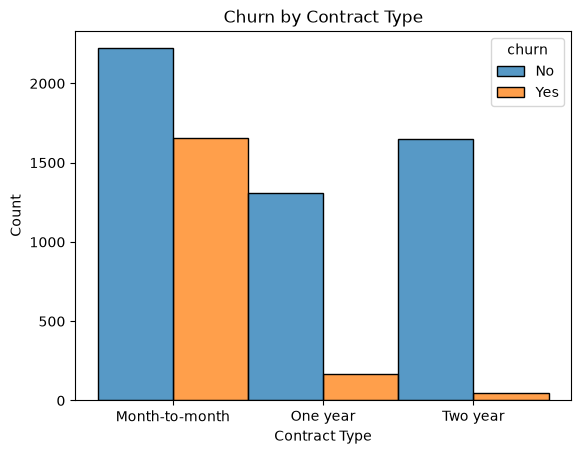

In [171]:
# Create and label the histogram comparison.
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=investigation1_df,
    x='contract',
    hue='churn',
    multiple='dodge'
)

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Count')
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram shows that month-to-month contracts are the most common group, followed by two-year and one-year contracts. Both churn categories appear in every contract group, although month-to-month customers appear to have more churn cases. The groups overlap because both churn outcomes occur within each contract type. The larger size of the month-to-month group makes its bars noticeably taller than the others.


In [172]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
investigation1_df.groupby('contract')['churn'].value_counts()

contract        churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

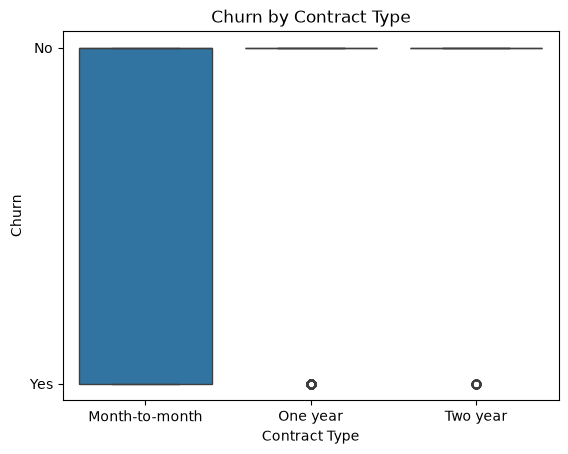

In [173]:
# Create and label the box-plot comparison.
sns.boxplot(
    data=investigation1_df,
    x='contract',
    y='churn'
)

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn')
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated counts support the visual estimates from the histogram. Month-to-month contracts had the largest number of customers (3,875) and the highest number of churn cases (1,655). One-year contracts had 1,473 customers with 166 churn cases, while two-year contracts had 1,695 customers with only 48 churn cases. The histogram clearly shows that churn is much more common among month-to-month customers. The box plot provides less useful information because churn is a categorical variable (Yes/No) rather than a quantitative measurement. The histogram is more effective for showing differences between the contract groups.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [187]:
# Perform a targeted check against original records or the declared group definitions.
investigation1_df['contract'].value_counts()

investigation1_df['churn'].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious if the counts of customers in the plots did not match the counts in the original dataset. My check confirmed that there are 5,174 customers who did not churn and 1,869 customers who did churn, which matches the records used in the analysis. The contract groups and churn categories appear valid, and no corrections were needed. There is no unresolved uncertainty from this check.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The analysis shows that churn differs across contract types. Month-to-month contracts had the highest number of churned customers, with 1,655 churn cases out of 3,875 customers. One-year contracts had 166 churn cases out of 1,473 customers, and two-year contracts had only 48 churn cases out of 1,695 customers. Although all contract groups contain both churn outcomes, customers with longer contracts were much less likely to churn. These results support my prediction that customers with one-year and two-year contracts would have lower churn rates than month-to-month customers.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader should not conclude that contract type alone causes customer churn. This dataset shows an association between contract type and churn, but other factors such as internet service, technical support, billing preferences, or customer characteristics may also influence whether a customer leaves. Therefore, the results should be interpreted as a comparison of distributions rather than proof of causation.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does customer churn differ between customers with and without technical support? The feature being analyzed is churn status (Yes/No), and the categorical groups are tech support status (Yes and No).


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that customers without technical support will have a higher proportion of churn than customers with technical support. I expect both groups to contain churn and non-churn cases, but the no-tech-support group may show more churn overall.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use all 7,043 customer records. The features used are tech_support and churn. The groups are customers with technical support and customers without technical support. No records will be excluded because there are no missing values. One observation represents one customer account.


In [200]:
# Prepare this question's analysis DataFrame and preview the selected features.
investigation2_df = telco_customer_df[['tech_support', 'churn']]

investigation2_df.head()

,tech_support,churn
0,No,No
1,No,No
2,No,Yes
3,Yes,No
4,No,Yes


In [201]:
# Display the number of usable observations in each group.
investigation2_df['tech_support'].value_counts()

tech_support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


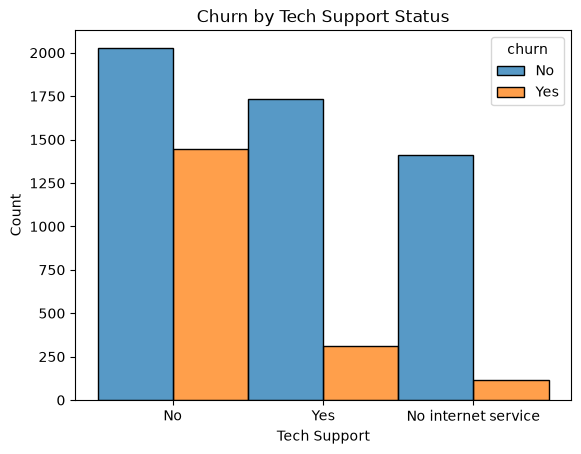

In [212]:
# Create and label the histogram comparison.
sns.histplot(
    data=investigation2_df,
    x='tech_support',
    hue='churn',
    multiple='dodge'
)

plt.title('Churn by Tech Support Status')
plt.xlabel('Tech Support')
plt.ylabel('Count')
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram shows that customers without technical support make up the largest group. Both churn outcomes appear in all tech support categories, but customers without technical support appear to have more churn cases. There is overlap because both churn outcomes occur within each group. The differences in group sizes affect the bar heights, making larger groups appear more prominent.


In [213]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
investigation2_df.groupby('tech_support')['churn'].value_counts()

tech_support         churn
No                   No       2027
                     Yes      1446
No internet service  No       1413
                     Yes       113
Yes                  No       1734
                     Yes       310
Name: count, dtype: int64

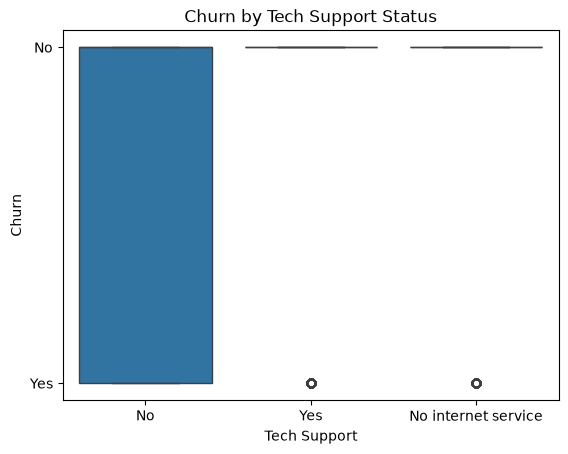

In [214]:
# Create and label the box-plot comparison.
sns.boxplot(
    data=investigation2_df,
    x='tech_support',
    y='churn'
)

plt.title('Churn by Tech Support Status')
plt.xlabel('Tech Support')
plt.ylabel('Churn')
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated summaries match the visual estimates from the histogram. Customers without technical support had the highest number of churn cases (1,446), while customers with technical support had only 310 churn cases. Customers with no internet service had the fewest churn cases (113). The histogram clearly shows these differences, while the box plot provides limited information because churn is a categorical Yes/No variable. The groups with technical support and no internet service appear more similar because both have relatively low numbers of churn cases compared to customers without technical support.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [222]:
# Perform a targeted check against original records or the declared group definitions.
investigation2_df['tech_support'].value_counts()

investigation2_df['churn'].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious if the churn totals did not match the counts shown in the visualizations or if unexpected values appeared in the churn variable. The check established that the dataset contains 5,174 customers who did not churn and 1,869 customers who did churn. These counts are consistent with the analysis and plots. The category values are valid, and no corrections or data conversions were necessary. There is no unresolved uncertainty from this check.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The analysis suggests that customers without technical support are more likely to churn than customers with technical support. The no-tech-support group had 1,446 churn cases, compared with 310 churn cases among customers with technical support. Customers with no internet service had only 113 churn cases. These results support my prediction that having technical support is associated with lower customer churn.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader should not conclude that technical support directly causes customers to stay with the company. Other factors, such as contract type, internet service type, or payment method, may also influence churn. This analysis shows an association between technical support status and churn but does not prove a cause-and-effect relationship.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: How does customer churn differ among customers using different payment methods? The feature being analyzed is churn status (Yes/No), and the categorical groups are the payment method categories.


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I predict that some payment methods will have higher churn rates than others. I expect overlap between all groups because both churn outcomes are likely present in each payment method category.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I will use all 7,043 customer records. The features used are payment_method and churn. The payment method categories will serve as the groups, and churn status is recorded as Yes or No. No records will be excluded because there are no missing values. One observation represents a single customer account.


In [229]:
# Prepare this question's analysis DataFrame and preview the selected features.
investigation3_df = telco_customer_df[['payment_method', 'churn']]

investigation3_df.head()

,payment_method,churn
0,Electronic check,No
1,Mailed check,No
2,Mailed check,Yes
3,Bank transfer (automatic),No
4,Electronic check,Yes


In [230]:
# Display the number of usable observations in each group.
investigation3_df['payment_method'].value_counts()

payment_method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


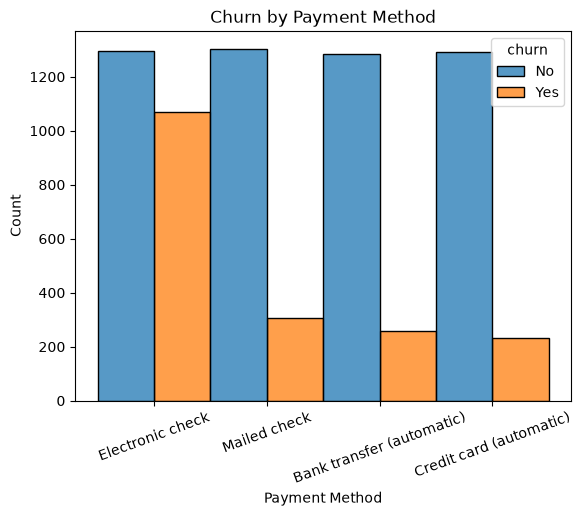

In [235]:
# Create and label the histogram comparison.
sns.histplot(
    data=investigation3_df,
    x='payment_method',
    hue='churn',
    multiple='dodge'
)

plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram shows that electronic check customers have the highest number of churn cases compared to the other payment methods. All payment methods contain both churn and non-churn customers, so there is overlap among the groups. Electronic check is the largest group with 2,365 customers, while the automatic payment methods and mailed check have smaller but similar group sizes. No unusual values are visible because all categories contain valid churn outcomes.


In [239]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
investigation3_df.groupby('payment_method')['churn'].value_counts()

payment_method             churn
Bank transfer (automatic)  No       1286
                           Yes       258
Credit card (automatic)    No       1290
                           Yes       232
Electronic check           No       1294
                           Yes      1071
Mailed check               No       1304
                           Yes       308
Name: count, dtype: int64

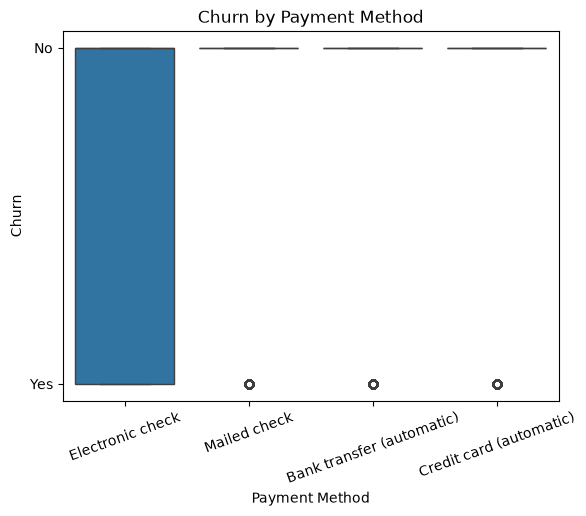

In [240]:
# Create and label the box-plot comparison.
sns.boxplot(
    data=investigation3_df,
    x='payment_method',
    y='churn'
)

plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn')
plt.xticks(rotation=20)
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The calculated summaries support the visual estimates from the histogram. Electronic check customers had the highest number of churn cases (1,071), which is much higher than mailed check (308), bank transfer (automatic) (258), and credit card (automatic) (232). All payment methods had a similar number of customers who did not churn, ranging from 1,286 to 1,304. The histogram clearly shows the differences in churn frequency across payment methods. The box plot hides much of this detail because churn is a categorical variable rather than a quantitative measurement. Electronic check appears most different from the other payment methods because it has substantially more churn cases.
 

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [242]:
# Perform a targeted check against original records or the declared group definitions.
investigation3_df['payment_method'].value_counts()

investigation3_df['churn'].value_counts()

churn
No     5174
Yes    1869
Name: count, dtype: int64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I would be suspicious if the payment-method counts shown in the histogram did not match the counts from the original dataset or if unexpected payment-method categories appeared. The check established that the payment-method groups contain the expected number of customers: 2,365 electronic check customers, 1,612 mailed check customers, 1,544 bank transfer (automatic) customers, and 1,522 credit card (automatic) customers. The check also confirmed that the churn variable contains 5,174 customers who did not churn and 1,869 customers who did churn. The records used in the analysis were consistent with the original dataset, so no corrections were necessary and there was no unresolved uncertainty.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: The analysis shows that customer churn varies by payment method. Customers using electronic checks had 1,071 churn cases, which was much higher than customers using mailed checks (308), bank transfers (258), or credit cards (232). All payment methods included both customers who churned and customers who did not churn, but the electronic check group had a noticeably larger number of churn cases. These results support my prediction that churn would differ among payment methods.
 

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader should not conclude that a customer's payment method directly causes churn. Other variables in the dataset, such as contract type, internet service, and technical support, may also influence whether a customer leaves the company. This analysis shows an association between payment method and churn, but it does not establish a cause-and-effect relationship.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used AI to help troubleshoot errors in my code and verify that my Python commands were running correctly. One suggestion I checked was how to create and label the histogram and box-plot visualizations using Seaborn. I compared the suggested code to my dataset and outputs before using it. I accepted the parts that correctly produced the required visualizations and modified some code and interpretations to match my dataset and assignment requirements. I also used AI to help identify and fix file-path and coding errors during the lab.


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
